In [19]:
import cv2              #Import the OpenCV Library
import numpy as np      #Import the Numpy library
import sys

from google.colab.patches import cv2_imshow
from skimage import io #  io.imread loads image as RGB

print ("You have successfully installed OpenCV version "+cv2.__version__)
print ("Your version of Python is " + sys.version)

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

from matplotlib import pyplot as plt # import matplotlib


def bgr_from_rgb(img):
  return img[:,:,::-1] # see https://scikit-image.org/docs/stable/user_guide/data_types.html

# v2.0 Added
def rgb_from_bgr(img):
  return img[:,:,::-1] # see https://scikit-image.org/docs/stable/user_guide/data_types.html

def load_image(url, as_gray=False):
  return bgr_from_rgb(io.imread(url, as_gray))

def load_image_gray(url):
  return cv2.imread(url, cv2.IMREAD_GRAYSCALE)

You have successfully installed OpenCV version 4.13.0
Your version of Python is 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [4]:
# Change to print your name:
print("Peter Bowman")

Peter Bowman


# Homework Tasks from Introduction to Computer Vision https://lrccd.instructure.com/courses/308168/pages/m14-lesson-6-36-15-introduction-to-computer-vision?module_item_id=26538514
Total Points: 12


*Version 1.1*


### Challenge 1 (2 Pts): Watch the video at https://www.youtube.com/watch?v=xyfSUOfFI_E
List down ideas of what you may like to create using the powers of Computer Vision. <br />
Can some of your ideas help to achieve the Sustainable Development Goals (SDG) https://sdgs.un.org/goals ?

In [1]:
# Detect Counterfit Money
# Road Sign to light up when animal is crossing road


print("Part 1 - Challenge 1 Done!")

Part 1 - Challenge 1 Done!


### Challenge 2 (2 Pts): List down at least 3 examples of Computer Vision applications that you have seen in the real world

In [3]:
# Red light detector
# workout exercise detector
# ASL translator to english

print("Part 1 - Challenge 2 Done!")

Part 1 - Challenge 2 Done!


### Challenge 3 (4 Pts): Expand on the video example in section 1.1b, resize the video to 800x600 and display it in greyscale

<IPython.core.display.Javascript object>

Saved to photo.jpg


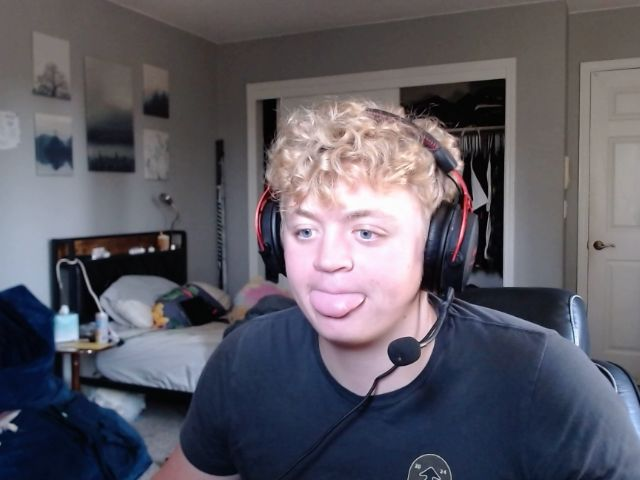

In [11]:
# 1.1b

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename
# your code here
from IPython.display import Image
try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

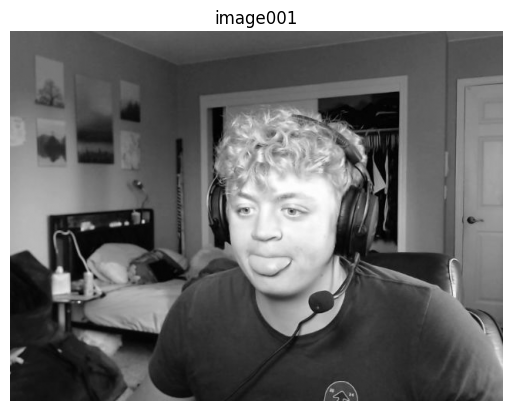

(480, 640)
Part 1 - Challenge 3 Done!


In [25]:


# Load color image (BGR) and convert to gray
img = cv2.imread("photo.jpg")
img_1 = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

plt.imshow(img_1, cmap="gray")
plt.title('image001')
plt.axis('off')
plt.show()

print(img_1.shape)
print("Part 1 - Challenge 3 Done!")



### Challenge 4 (4 Pts): Use the Python time library, and add a timestamp neatly to the video feed from your webcam

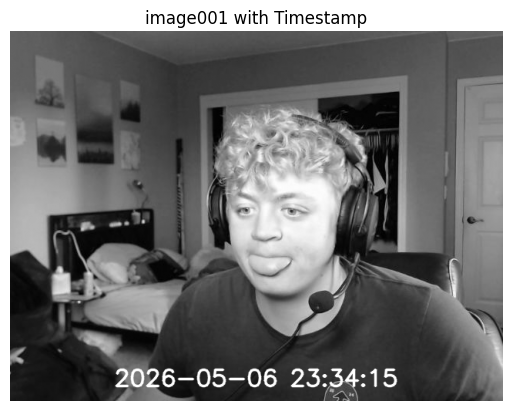

Part 1 - Challenge 4 Done!


In [32]:
# Sample Code for getting a timestamp. Search online for more options if you need.
from datetime import datetime
ts = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# Add text to the grayscale image
# Make a copy to avoid modifying the original img_1 if it's used elsewhere
img_with_text = img_1.copy()

font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 1
color = 255 # White color for grayscale image
thickness = 2

# Get text size for positioning
text_size = cv2.getTextSize(ts, font, font_scale, thickness)[0]
text_x = (img_with_text.shape[1] - text_size[0]) // 2 # Center horizontally
text_y = img_with_text.shape[0] - 20 # 20 pixels from the bottom

cv2.putText(img_with_text, ts, (text_x, text_y), font, font_scale, color, thickness, cv2.LINE_AA)

plt.imshow(img_with_text, cmap='gray')
plt.title('image001 with Timestamp')
plt.axis('off')
plt.show()


print("Part 1 - Challenge 4 Done!")

# Homework Tasks from Computer Vision and Machine Learning https://lrccd.instructure.com/courses/308168/pages/m14-lesson-7-38-55-computer-vision-and-machine-learning?module_item_id=26538516

Total points: 21

### Challenge 1 (3 Pts): What is the average color of https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/test/58.png ?

Store the result in a variable "cha1"

In [36]:
# Your code here

img2 = load_image("https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/test/58.png")
cha1 = np.mean(img2)
print(f"Shape of img2: {img2.shape}")
print(f"Average color (cha1): {cha1}")
print("Part 2 - Challenge 1 Done!")

Shape of img2: (480, 640, 3)
Average color (cha1): 184.38657769097222
Part 2 - Challenge 1 Done!


### Challenge 2 (3 Pts): What is the average color of https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/background.png ?

Store the result in a variable "cha2"

In [39]:
# Your code here
img2 = load_image("https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/background.png")

cha2 = np.mean(img2)
print(f"Shape of img2: {img2.shape}")
print(f"Average color (cha1): {cha2}")

print("Part 2 - Challenge 2 Done!")

Shape of img2: (480, 640, 3)
Average color (cha1): 243.6558908420139
Part 2 - Challenge 2 Done!


### Challenge 3 (3 Pts): What is the average color of https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/cardgreen_close.png ?

Store the result in a variable "cha3"

In [40]:

# Your code here
img2 = load_image("https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/cardgreen_close.png")

cha3 = np.mean(img2)
print(f"Shape of img2: {img2.shape}")
print(f"Average color (cha1): {cha3}")

print("Part 2 - Challenge 3 Done!")

Shape of img2: (480, 640, 3)
Average color (cha1): 104.68402886284723
Part 2 - Challenge 3 Done!


### Challenge 4 (3 Pts): 58.png vs Background. Calculate the distance between cha1 and cha2

Recall how the euclidean distance was calculated in section 1.2

In [42]:
# Using Euclidean distance as discussed in section 1.2
dist_1_2 = np.linalg.norm(cha1 - cha2)
print(f"Distance between 58.png and Background: {dist_1_2}")
print("Part 2 - Challenge 4 Done!")

Distance between 58.png and Background: 59.26931315104167
Part 2 - Challenge 4 Done!


### Challenge 5 (3 Pts): 58.png vs Green. Calculate the distance between cha1 and cha3

Recall how the euclidean distance was calculated in section 1.2

In [43]:
dist_1_3 = np.linalg.norm(cha1 - cha3)
print(f"Distance between 58.png and Green: {dist_1_3}")
print("Part 2 - Challenge 5 Done!")

Distance between 58.png and Green: 79.70254882812499
Part 2 - Challenge 5 Done!


A smaller distance implies a greater similarity. Hence, 58.png was classified as more similar to the background, than to the green card based on the 4 "training images".

### Challenge 6 (3 Pts): Modify the function averagecolor to convert the image to greyscale before extracting the features

Recall how you converted an image to greyscale in the previous workshop. Calculate the accuracy of the kNN model when we use average greyscale instead of averagecolor. (i.e. Run section 1.3 using your updated averagecolor function. Rerun both the training and inference steps) What is the new accuracy? Does it perform better? Why do you think so?

In [47]:
def averagecolor_grey(image):
    if len(image.shape) == 3:
        grey_img = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        grey_img = image
    return np.mean(grey_img)

# Example of using the updated feature extraction for distances
feat1 = averagecolor_grey(load_image("https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/test/58.png"))
feat2 = averagecolor_grey(load_image("https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/background.png"))
feat3 = averagecolor_grey(load_image("https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/cardgreen_close.png"))

grey_dist_1_2 = np.abs(feat1 - feat2)
grey_dist_1_3 = np.abs(feat1 - feat3)

print(f"Grayscale Average - 58 vs Background: {grey_dist_1_2}")
print(f"Grayscale Average - 58 vs Green Card: {grey_dist_1_3}")

# accuracy decreases because the amount of features we're comparing it decreases

print('\nPart 2 - Challenge 6 Done!')

Grayscale Average - 58 vs Background: 50.81628580729168
Grayscale Average - 58 vs Green Card: 80.95367838541667

Part 2 - Challenge 6 Done!


### Challenge 7 (3 Pts): Which distance calculation metric does the sklearn kNN model use by default? Is it also the euclidean distance that we used?

You can look up https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

In [48]:
print("The default metric is 'minkowski' with p=2, which is Euclidean distance.")
print("Part 2 - Challenge 7 Done!")

The default metric is 'minkowski' with p=2, which is Euclidean distance.
Part 2 - Challenge 7 Done!


### Extra Credit (only attempt if above challenges completed)
### Challenge 8 (4 Pts): Using the kNN algorithm, mask out just the red card from https://ethaneldridge.github.io/cisc499/Module14-07-ComputerVisionAndMachineLearning/cardmixed.png, and calculate the fraction of red pixels vs. total number of pixels in that image

Note: In this case, we happened to be able to use the model to predict the class of each pixel because our model was built using color as a feature. However this method may not always be applicable depending on the features used for different models. You can search the Internet to explore other methods of localization.

Artificial Neural Networks (ANN), specifically Convolutional Neural Networks (CNN) have recently become very popular due to their much higher level of effectiveness. In the next workshop, we will explore the use of some pre-trained CNNs, together with how we might run inferences using the Intel Movidus Neural Compute Stick 2 (NCS2), that is powered by the Intel Myriad VPU.

Have you heard of the DJI Tello drones? They make use of computer vision to improve the flight quality too, and they are also powered by an Intel MYRIAD VPU!
https://www.movidius.com/news/hello-tello-ryze-announces-intel-myriad-vpu-powered-toy-drone

If you remember, earlier in this lesson we also discussed about complementing machine vision with other sensors. What other sensors do you think are onboard the Tello drone apart from the camera?
https://www.ryzerobotics.com/tello/specs

What do you think the range finder and the barometer are used to sense?